# Mapa inverso aprendido y prueba

**Pregunta:** En las mismas realizaciones sintéticas retenidas, ¿cómo se compara el error CNN de densidad integrada con la inversión clásica?
**Nivel 1 — Fundamentos**  
**Prerrequisitos:** nociones de Python; 35 min.

## Objetivos

Reconstruya errores CNN en unidades físicas desde la normalización guardada y compárelos por caso con el inverso clásico en las mismas realizaciones retenidas.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

El ledger guarda particiones, errores normalizados, métricas y evaluación OOD separada.

## Método

M12 predice columna de densidad integrada en profundidad desde entradas gravimétricas; no es modelo 3D. Ledger: 800/160/160 realizaciones train/validación/prueba, semillas disjuntas y geometrías oblicuas/anulares retenidas fuera del entrenamiento. Baseline clásico y CNN comparten 160 pruebas. MSE guardado: 1466,24 y 680,15 `(g·cm⁻³·m)²`. Reconstruya errores pareados CNN usando escala objetivo al cuadrado, grafique comparación y diferencia, e informe fracción mejorada y ganancia mediana. Evalúa un generador sintético y su partición, no geología de campo, cambios de adquisición ni calibración de incertidumbre; el promedio puede ocultar regresiones.

Este benchmark predice una columna de densidad integrada, no un modelo terrestre 3D. Deshaga la normalización multiplicando los errores CNN al cuadrado por target_scale² antes de calcular MSE físico. La partición por realización evita cruces de modelos sintéticos relacionados, pero 160 casos siguen muestreando un generador y no prueban transferencia a geología o adquisición nuevas.

## Resultados

**Respuesta:** La inferencia CNN fresca reproduce 160 errores retenidos. El MSE físico es 755.757 (g/cm³·m)² frente a 1441.328 del inverso clásico pareado en los mismos casos sintéticos.

## Resumen

La CNN congelada reduce error medio para una columna integrada en este generador. No recupera estructura 3D; se necesita otro sitio y diseño de adquisición para evaluar transferencia.

## Referencias

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)


### Diagnóstico 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
import json

print("Versiones del entorno:", {name: version(name) for name in ["numpy", "matplotlib"]})
import numpy as np

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)
# Cargue los errores pareados de prueba y deshaga la normalización declarada del objetivo CNN en el registro.
d = json.loads((root / "data/derived/v2/models/training.json").read_text(encoding="utf-8"))
a = np.asarray(d["classical_test_errors"], float)
b = np.asarray(d["models"]["cnn"]["test_errors"], float) * d["target_scale"] ** 2


Versiones del entorno: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}


### Cargue la CNN y el autoencoder congelados junto con el operador gravimétrico usado para construir el benchmark. El cargador del paquete verifica los metadatos del checkpoint y expone las escalas de normalización, necesarias para volver a expresar las salidas del modelo en unidades físicas de densidad. Cargar pesos no es entrenar y el conjunto de prueba permanece intacto durante la selección del modelo.

In [2]:
print(
    "splits",
    d["split_counts"],
    d["split_policy"],
    "casos",
    len(a),
    "unit",
    d["units"],
    "stored MSE",
    d["classical_test_mse"],
    d["cnn_test_mse"],
    "recomputed",
    a.mean(),
    b.mean(),
)
# Cargue el checkpoint entrenado y el operador directo usados por el benchmark.
import sys, torch, hashlib

sys.path.insert(0, str(root / "data-pipeline"))
import geology, learning, potential

cnn_model, ae_model, training_meta = learning.load_bundle(root / "data/derived/v2/models")
mesh_real, _, G_real, _ = potential.operators()


splits [800, 160, 160] Disjoint generator seeds; complete realization assigned to one split; oblique and ring geometries withheld from training casos 160 unit (g/cm³ m)² stored MSE 1441.3277421693122 755.7566463947296 recomputed 1441.3277421693124 755.7565736933611


### Diagnóstico 2

Calcule la comparación y grafíquela con unidades físicas.

Fracción donde CNN es mejor 0.79375 ganancia mediana 469.33024381926634 (g/cm³ m)²


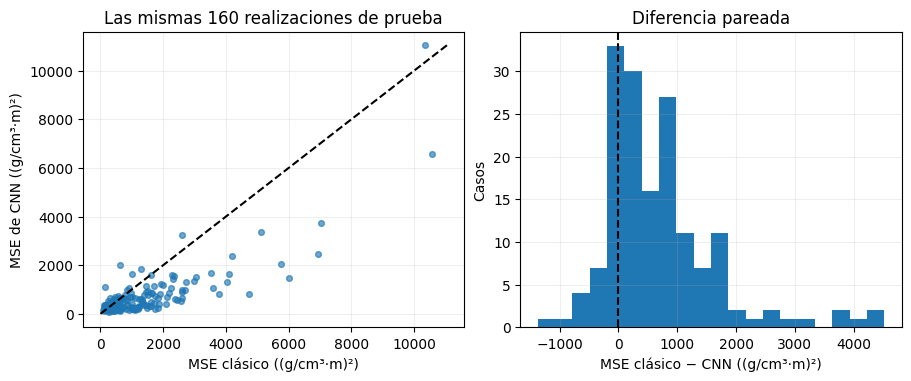

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Compare los errores pareados; los puntos bajo la diagonal son casos donde el MSE de la CNN es menor.
import matplotlib.pyplot as plt

delta = a - b
lim = max(a.max(), b.max())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.7), constrained_layout=True)
ax[0].scatter(a, b, s=17, alpha=0.65)
ax[0].plot([0, lim], [0, lim], "k--")
ax[0].set(
    xlabel="MSE clásico ((g/cm³·m)²)", ylabel="MSE de CNN ((g/cm³·m)²)", title="Las mismas 160 realizaciones de prueba"
)
ax[1].hist(delta, bins=20)
ax[1].axvline(0, color="black", ls="--")
ax[1].set(xlabel="MSE clásico − CNN ((g/cm³·m)²)", ylabel="Casos", title="Diferencia pareada")
[x.grid(alpha=0.2) for x in ax]
print("Fracción donde CNN es mejor", (delta > 0).mean(), "ganancia mediana", np.median(delta), d["units"])
plt.show()


### Experimento: incertidumbre pareada dentro del generador de prueba declarado

La partición train/dev/test usa realizaciones sintéticas completas y semillas de generador disjuntas; las familias oblicuas y anulares se retienen deliberadamente fuera del entrenamiento. Recalcule un intervalo bootstrap pareado para la diferencia MSE media por realización `clásico − CNN` en los **mismos 160 casos de prueba**. Esto cuantifica incertidumbre de muestreo solo dentro de este generador. No estima incertidumbre entre sitios reales, geologías alternativas, geometrías de levantamiento ni leyes de ruido. Verifique los conteos y la normalización almacenados antes de interpretar el intervalo; no use este intervalo de prueba para seleccionar épocas o hiperparámetros.

In [4]:
# Bootstrap pareado: remuestree realizaciones y conserve la comparación con entradas idénticas.
assert d["split_counts"] == [800, 160, 160] and len(a) == len(b) == 160
assert np.isclose(b.mean(), d["cnn_test_mse"], rtol=1e-6)
rng = np.random.default_rng(20261027)
boot = np.empty(5000)
for j in range(len(boot)):
    idx = rng.integers(0, len(a), len(a))
    boot[j] = np.mean(a[idx] - b[idx])
lo, hi = np.quantile(boot, [0.025, 0.975])
print(
    (f"Diferencia media pareada (clásico-CNN)={np.mean(a-b):.3f} (g/cm^3 m)^2; "
     f"intervalo bootstrap 95% [{lo:.3f}, {hi:.3f}]")
)
print("El bootstrap remuestrea realizaciones, no vóxeles; el intervalo no cubre cambio de dominio de campo.")


Diferencia media pareada (clásico-CNN)=685.571 (g/cm^3 m)^2; intervalo bootstrap 95% [540.350, 840.856]
El bootstrap remuestrea realizaciones, no vóxeles; el intervalo no cubre cambio de dominio de campo.


### Reconstruir la cohorte de prueba completa

La semilla de prueba registrada genera la cohorte completa de 160 casos en la malla física. El operador gravimétrico comprometido produce las entradas sintéticas reales del benchmark; no es un lote ilustrativo pequeño.


In [5]:
# Regenere los 160 volúmenes de prueba y observaciones gravimétricas exactos a partir de la semilla del registro.
test_models = learning.generate(mesh_real.cell_centers, 160, training_meta["seeds"][2])
test_clean = test_models @ G_real.T
print("modelos de prueba y observaciones limpias", test_models.shape, test_clean.shape)


modelos de prueba y observaciones limpias (160, 10752) (160, 1024)


### Verificar los bytes de ruido registrados

El flujo aleatorio avanza por entrenamiento y validación antes de prueba. Su digest se compara con el ledger y vincula observaciones reconstruidas con la entrada benchmark, no con otra realización parecida.


In [6]:
# Avance el flujo de ruido documentado a través de entrenamiento y validación antes de la prueba.
noise_rng = np.random.default_rng(5001)
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (800, G_real.shape[0]))
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (160, G_real.shape[0]))
test_noise = noise_rng.normal(0, 0.02 * training_meta["input_scale"], test_clean.shape)
test_input = test_clean + test_noise
test_sha = hashlib.sha256(test_input.astype("<f8").tobytes()).hexdigest()
assert test_sha == training_meta["comparison"]["noisy_test_sha256"]
print("SHA-256 de entrada retenida verificado", test_sha)


SHA-256 de entrada retenida verificado 75fee10c9c19cff26ae51a02258ddd24c1958bf812c8b445abb3881e35b29940


### Inferir con CNN congelada

La CNN congelada predice densidad integrada en profundidad para las observaciones ruidosas exactas. El blanco se proyecta desde cada realización 3D sintética con espaciamiento vertical físico; no se actualizan pesos.


In [7]:
# Infiera el objetivo de densidad integrada en profundidad con las observaciones retenidas exactas y con ruido.
from geology import VOLUME_SHAPE, VOLUME_SPACING

x_test = torch.as_tensor(
    test_input / training_meta["input_scale"], dtype=torch.float32, device=next(cnn_model.parameters()).device
).reshape(-1, 1, *training_meta["survey_shape"])
y_test = test_models.reshape(-1, *VOLUME_SHAPE).sum(1) * VOLUME_SPACING[2] / training_meta["target_scale"]
with torch.no_grad():
    pred_test = cnn_model(x_test).cpu().numpy()
cnn_errors = np.mean((pred_test - y_test) ** 2, axis=(1, 2))
print("casos inferidos", len(cnn_errors), "MSE normalizado medio", float(cnn_errors.mean()))


casos inferidos 160 MSE normalizado medio 0.004723478481682726


### Verificar errores pareados

Los errores por caso se llevan a unidades físicas y se cotejan con el ledger. El comparador clásico usa observaciones pareadas. El resultado depende del generador sintético y no muestra recuperación 3D.


In [8]:
# Reconstruya los errores pareados de la CNN en unidades físicas y verifique cada caso de prueba registrado.
cnn_mse_physical = cnn_errors * training_meta["target_scale"] ** 2
recorded_cnn = np.asarray(training_meta["models"]["cnn"]["test_errors"]) * training_meta["target_scale"] ** 2
assert np.allclose(cnn_mse_physical, recorded_cnn, rtol=2e-4, atol=2e-4)
classical_mse = np.asarray(training_meta["classical_test_errors"])
print("MSE físico de CNN", float(cnn_mse_physical.mean()), "clásico", float(classical_mse.mean()))


MSE físico de CNN 755.7565570692364 clásico 1441.3277421693124


### Evaluar la recuperación de columna en unidades físicas

La salida CNN y el objetivo sintético integrado vuelven a unidades de densidad por profundidad antes de aplicar el diagnóstico común. El modelo cero es la referencia declarada por el evaluador. La métrica describe proyecciones sintéticas retenidas, no localización 3D en profundidad.


In [9]:
# Evalúe las estimaciones retenidas de columna con el evaluador del repositorio.
from evaluation import model_metrics

physical_prediction = pred_test * training_meta["target_scale"]
physical_truth = y_test * training_meta["target_scale"]
heldout_recovery = model_metrics(physical_prediction, physical_truth)
print("RMSE de columna retenida", heldout_recovery["model_rmse"])
print("razón frente a inicio cero", heldout_recovery["baseline_ratio"])


RMSE de columna retenida 27.491026845187832
razón frente a inicio cero 0.36162633287599516
